In [3]:
%pip install -q \
    "transformers==4.57.6" \
    "huggingface-hub==0.36.2" \
    "datasets==4.8.5" \
    "tokenizers==0.22.2" \
    "sentencepiece" \
    "sacrebleu" \
    "evaluate" \
    "accelerate" \
    "peft" \
    "bitsandbytes"

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.30.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.42.0 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.


In [4]:
import torch
import transformers
import datasets
import huggingface_hub
import sentencepiece
import sacrebleu
import accelerate
import peft
import bitsandbytes

print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "Not available")
print("Transformers:", transformers.__version__)
print("Datasets:", datasets.__version__)
print("Hugging Face Hub:", huggingface_hub.__version__)
print("All required imports successful!")

GPU: Tesla T4
Transformers: 4.57.6
Datasets: 4.8.5
Hugging Face Hub: 0.36.2
All required imports successful!


In [5]:
from datasets import load_dataset
import pandas as pd

# Load English-French parallel translation dataset
dataset = load_dataset(
    "Helsinki-NLP/opus_books",
    "en-fr",
    split="train"
)

print("Total available examples:", len(dataset))
print("\nFirst example:")
print(dataset[0])

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md: 0.00B [00:00, ?B/s]

en-fr/train-00000-of-00001.parquet:   0%|          | 0.00/21.0M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/127085 [00:00<?, ? examples/s]

Total available examples: 127085

First example:
{'id': '0', 'translation': {'en': 'The Wanderer', 'fr': 'Le grand Meaulnes'}}


In [6]:
from datasets import Dataset
import pandas as pd

# Extract valid English-French sentence pairs
pairs = []

for example in dataset:
    en = example["translation"]["en"].strip()
    fr = example["translation"]["fr"].strip()

    # Remove empty and unusually long sentences
    if (
        en and fr
        and 3 <= len(en.split()) <= 35
        and 3 <= len(fr.split()) <= 40
    ):
        pairs.append({"en": en, "fr": fr})

# Convert to Hugging Face Dataset
clean_dataset = Dataset.from_list(pairs)

# Shuffle reproducibly and select 6000 examples
clean_dataset = clean_dataset.shuffle(seed=42)
clean_dataset = clean_dataset.select(
    range(min(6000, len(clean_dataset)))
)

# Create train, validation, and test splits
first_split = clean_dataset.train_test_split(
    test_size=0.2,
    seed=42
)

second_split = first_split["test"].train_test_split(
    test_size=0.5,
    seed=42
)

train_data = first_split["train"]
val_data = second_split["train"]
test_data = second_split["test"]

print("Training examples:", len(train_data))
print("Validation examples:", len(val_data))
print("Testing examples:", len(test_data))

print("\nSample translation:")
print("English:", train_data[0]["en"])
print("French:", train_data[0]["fr"])

Training examples: 4800
Validation examples: 600
Testing examples: 600

Sample translation:
English: Things have taken a turn which I could not have anticipated.
French: Les choses ont pris un cours que je ne pouvais pas prévoir.


In [7]:
import re
from collections import Counter
import torch

SPECIAL = ["<pad>", "<unk>", "<bos>", "<eos>"]

def tokenize(text):
    return re.findall(r"\w+|[^\w\s]", text.lower(), flags=re.UNICODE)

def build_vocab(texts, max_size=8000):
    counts = Counter()
    for text in texts:
        counts.update(tokenize(text))

    vocab = SPECIAL + [
        word for word, _ in counts.most_common(max_size - len(SPECIAL))
        if word not in SPECIAL
    ]
    return {word: i for i, word in enumerate(vocab)}

src_vocab = build_vocab(train_data["en"])
tgt_vocab = build_vocab(train_data["fr"])

src_unk = src_vocab["<unk>"]
tgt_unk = tgt_vocab["<unk>"]

def encode(text, vocab, max_len=40):
    ids = [vocab["<bos>"]]
    ids += [vocab.get(w, vocab["<unk>"]) for w in tokenize(text)]
    ids = ids[:max_len - 1]
    ids.append(vocab["<eos>"])
    return ids

print("English vocabulary:", len(src_vocab))
print("French vocabulary:", len(tgt_vocab))
print("GPU:", torch.cuda.get_device_name(0))

English vocabulary: 8000
French vocabulary: 8000
GPU: Tesla T4


In [8]:
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence

class TranslationDataset(Dataset):
    def __init__(self, data):
        self.data = data

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        item = self.data[idx]
        src = torch.tensor(encode(item["en"], src_vocab), dtype=torch.long)
        tgt = torch.tensor(encode(item["fr"], tgt_vocab), dtype=torch.long)
        return src, tgt

def collate_batch(batch):
    src, tgt = zip(*batch)
    src = pad_sequence(src, batch_first=True, padding_value=0)
    tgt = pad_sequence(tgt, batch_first=True, padding_value=0)
    return src, tgt

train_loader = DataLoader(
    TranslationDataset(train_data),
    batch_size=64,
    shuffle=True,
    collate_fn=collate_batch
)

val_loader = DataLoader(
    TranslationDataset(val_data),
    batch_size=64,
    shuffle=False,
    collate_fn=collate_batch
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

Training batches: 75
Validation batches: 10


In [9]:
import math
import torch.nn as nn

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

class PositionalEncoding(nn.Module):
    def __init__(self, d_model=128, max_len=100):
        super().__init__()

        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len).unsqueeze(1)

        div_term = torch.exp(
            torch.arange(0, d_model, 2) *
            (-math.log(10000.0) / d_model)
        )

        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)

        self.register_buffer("pe", pe.unsqueeze(0))

    def forward(self, x):
        return x + self.pe[:, :x.size(1)]

class BasicTransformer(nn.Module):
    def __init__(self, src_size, tgt_size, d_model=128):
        super().__init__()

        self.src_embed = nn.Embedding(src_size, d_model, padding_idx=0)
        self.tgt_embed = nn.Embedding(tgt_size, d_model, padding_idx=0)
        self.positional = PositionalEncoding(d_model)

        self.transformer = nn.Transformer(
            d_model=d_model,
            nhead=4,
            num_encoder_layers=2,
            num_decoder_layers=2,
            dim_feedforward=256,
            dropout=0.1,
            batch_first=True
        )

        self.fc = nn.Linear(d_model, tgt_size)
        self.scale = math.sqrt(d_model)

    def forward(self, src, tgt):
        src_padding = src.eq(0)
        tgt_padding = tgt.eq(0)

        tgt_mask = nn.Transformer.generate_square_subsequent_mask(
            tgt.size(1), device=tgt.device
        )

        src_emb = self.positional(self.src_embed(src) * self.scale)
        tgt_emb = self.positional(self.tgt_embed(tgt) * self.scale)

        output = self.transformer(
            src_emb,
            tgt_emb,
            tgt_mask=tgt_mask,
            src_key_padding_mask=src_padding,
            tgt_key_padding_mask=tgt_padding,
            memory_key_padding_mask=src_padding
        )

        return self.fc(output)

basic_model = BasicTransformer(
    len(src_vocab),
    len(tgt_vocab)
).to(device)

print("Basic Transformer created successfully!")
print("Parameters:", sum(p.numel() for p in basic_model.parameters()))

Basic Transformer created successfully!
Parameters: 3743040


In [10]:
import time
import torch.optim as optim

criterion = nn.CrossEntropyLoss(ignore_index=0)
optimizer = optim.Adam(basic_model.parameters(), lr=0.0005)

EPOCHS = 5
basic_history = {"train_loss": [], "val_loss": []}

start_time = time.time()

for epoch in range(EPOCHS):

    # Training
    basic_model.train()
    train_loss = 0

    for src, tgt in train_loader:
        src = src.to(device)
        tgt = tgt.to(device)

        optimizer.zero_grad()

        # Teacher forcing: predict the next French token
        output = basic_model(src, tgt[:, :-1])

        loss = criterion(
            output.reshape(-1, output.size(-1)),
            tgt[:, 1:].reshape(-1)
        )

        loss.backward()
        torch.nn.utils.clip_grad_norm_(basic_model.parameters(), 1.0)
        optimizer.step()

        train_loss += loss.item()

    # Validation
    basic_model.eval()
    val_loss = 0

    with torch.no_grad():
        for src, tgt in val_loader:
            src = src.to(device)
            tgt = tgt.to(device)

            output = basic_model(src, tgt[:, :-1])

            loss = criterion(
                output.reshape(-1, output.size(-1)),
                tgt[:, 1:].reshape(-1)
            )

            val_loss += loss.item()

    avg_train = train_loss / len(train_loader)
    avg_val = val_loss / len(val_loader)

    basic_history["train_loss"].append(avg_train)
    basic_history["val_loss"].append(avg_val)

    print(
        f"Epoch {epoch+1}/{EPOCHS} | "
        f"Train Loss: {avg_train:.4f} | "
        f"Val Loss: {avg_val:.4f}"
    )

basic_training_time = time.time() - start_time

print("\nTraining completed!")
print(f"Total training time: {basic_training_time:.2f} seconds")

/usr/local/lib/python3.13/dist-packages/torch/nn/modules/activation.py:1336: UserWarning: Support for mismatched key_padding_mask and attn_mask is deprecated. Use same type for both instead.
  key_padding_mask = F._canonical_mask(
/usr/local/lib/python3.13/dist-packages/torch/nn/modules/transformer.py:531: UserWarning: The PyTorch API of nested tensors is in prototype stage and will change in the near future. We recommend specifying layout=torch.jagged when constructing a nested tensor, as this layout receives active development, has better operator coverage, and works with torch.compile. (Triggered internally at /pytorch/aten/src/ATen/NestedTensorImpl.cpp:178.)
  output = torch._nested_tensor_from_mask(


Epoch 1/5 | Train Loss: 6.8232 | Val Loss: 5.3966
Epoch 2/5 | Train Loss: 5.5752 | Val Loss: 4.9401
Epoch 3/5 | Train Loss: 5.1847 | Val Loss: 4.6917
Epoch 4/5 | Train Loss: 4.9284 | Val Loss: 4.5199
Epoch 5/5 | Train Loss: 4.7369 | Val Loss: 4.4140

Training completed!
Total training time: 19.70 seconds


In [12]:
import torch

torch.save({
    "model_state_dict": basic_model.state_dict(),
    "src_vocab": src_vocab,
    "tgt_vocab": tgt_vocab,
    "history": basic_history,
    "training_time": basic_training_time
}, "basic_transformer_checkpoint.pt")

print("Basic Transformer checkpoint saved!")

Basic Transformer checkpoint saved!


In [13]:
import time
import pandas as pd
import sacrebleu
import torch

# Reverse French vocabulary
id_to_tgt = {idx: word for word, idx in tgt_vocab.items()}

@torch.inference_mode()
def translate_basic(text, max_len=40):
    basic_model.eval()

    src_ids = encode(text, src_vocab)
    src = torch.tensor([src_ids], dtype=torch.long, device=device)

    generated = [tgt_vocab["<bos>"]]

    for _ in range(max_len):
        tgt = torch.tensor(
            [generated], dtype=torch.long, device=device
        )

        logits = basic_model(src, tgt)
        next_id = logits[0, -1].argmax().item()

        if next_id == tgt_vocab["<eos>"]:
            break

        generated.append(next_id)

    words = [
        id_to_tgt.get(i, "<unk>")
        for i in generated[1:]
        if i not in (0, 2, 3)
    ]

    result = " ".join(words)
    result = result.replace(" ' ", "'")
    result = result.replace(" ,", ",").replace(" .", ".")
    result = result.replace(" !", "!").replace(" ?", "?")

    return result

# Test translation
sample = "Things have taken a turn which I could not have anticipated."

print("English:", sample)
print("Generated French:", translate_basic(sample))

English: Things have taken a turn which I could not have anticipated.
Generated French: je ne me pas pas pas pas pas pas.


In [14]:
import time
import pandas as pd
import sacrebleu

# Use the same fixed test subset for all four models
EVAL_SIZE = 100
eval_data = test_data.select(range(min(EVAL_SIZE, len(test_data))))

sources = eval_data["en"]
references = eval_data["fr"]

basic_predictions = []

start = time.perf_counter()

for i, sentence in enumerate(sources):
    translation = translate_basic(sentence)
    basic_predictions.append(translation)

    if (i + 1) % 10 == 0:
        print(f"Translated {i + 1}/{len(sources)} sentences")

if torch.cuda.is_available():
    torch.cuda.synchronize()

basic_inference_time = time.perf_counter() - start

basic_bleu = sacrebleu.corpus_bleu(
    basic_predictions, [references]
).score

basic_chrf = sacrebleu.corpus_chrf(
    basic_predictions, [references]
).score

basic_params = sum(p.numel() for p in basic_model.parameters())

print("\nBASIC TRANSFORMER RESULTS")
print("BLEU:", round(basic_bleu, 4))
print("chrF:", round(basic_chrf, 4))
print("Inference time:", round(basic_inference_time, 2), "seconds")
print("Parameters:", basic_params)

# Save translations
basic_results = pd.DataFrame({
    "English": sources,
    "Reference_French": references,
    "Basic_Transformer": basic_predictions
})

basic_results.to_csv("basic_transformer_translations.csv", index=False)

# Save evaluation metrics
basic_metrics = {
    "Model": "Basic Transformer",
    "BLEU": basic_bleu,
    "chrF": basic_chrf,
    "Training_seconds": basic_training_time,
    "Inference_seconds": basic_inference_time,
    "Parameters": basic_params
}

pd.DataFrame([basic_metrics]).to_csv(
    "basic_transformer_metrics.csv", index=False
)

print("\nResults saved successfully!")

Translated 10/100 sentences
Translated 20/100 sentences
Translated 30/100 sentences
Translated 40/100 sentences
Translated 50/100 sentences
Translated 60/100 sentences
Translated 70/100 sentences
Translated 80/100 sentences
Translated 90/100 sentences
Translated 100/100 sentences

BASIC TRANSFORMER RESULTS
BLEU: 0.221
chrF: 6.0839
Inference time: 11.75 seconds
Parameters: 3743040

Results saved successfully!


In [15]:
import torch
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

mt5_name = "google/mt5-small"

mt5_tokenizer = AutoTokenizer.from_pretrained(mt5_name)

mt5_model = AutoModelForSeq2SeqLM.from_pretrained(
    mt5_name
).to(device)

mt5_params = sum(p.numel() for p in mt5_model.parameters())

print("mT5 loaded successfully!")
print("Parameters:", mt5_params)
print("Device:", next(mt5_model.parameters()).device)

tokenizer_config.json:   0%|          | 0.00/82.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/553 [00:00<?, ?B/s]

spiece.model:   0%|          | 0.00/4.31M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/99.0 [00:00<?, ?B/s]

You are using the default legacy behaviour of the <class 'transformers.models.t5.tokenization_t5.T5Tokenizer'>. This is expected, and simply means that the `legacy` (previous) behavior will be used so nothing changes for you. If you want to use the new behaviour, set `legacy=False`. This should only be set if you understand what it means, and thoroughly read the reason why this was added as explained in https://github.com/huggingface/transformers/pull/24565
/usr/local/lib/python3.13/dist-packages/transformers/convert_slow_tokenizer.py:566: UserWarning: The sentencepiece tokenizer that you are converting to a fast tokenizer uses the byte fallback option which is not implemented in the fast tokenizers. In practice this means that the fast version of the tokenizer can produce unknown tokens whereas the sentencepiece version would have converted these unknown tokens into a sequence of byte tokens matching the original piece of text.
  warnings.warn(


pytorch_model.bin:   0%|          | 0.00/1.20G [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/1.20G [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

mT5 loaded successfully!
Parameters: 300176768
Device: cuda:0


In [16]:
from torch.utils.data import DataLoader
from transformers import DataCollatorForSeq2Seq

# Use a manageable subset for T4 GPU
mt5_train = train_data.select(range(1000))
mt5_val = val_data.select(range(100))

def preprocess_mt5(batch):
    inputs = [
        "translate English to French: " + text
        for text in batch["en"]
    ]

    model_inputs = mt5_tokenizer(
        inputs,
        max_length=64,
        truncation=True
    )

    labels = mt5_tokenizer(
        text_target=batch["fr"],
        max_length=64,
        truncation=True
    )

    model_inputs["labels"] = labels["input_ids"]
    return model_inputs

mt5_train_tokenized = mt5_train.map(
    preprocess_mt5,
    batched=True,
    remove_columns=mt5_train.column_names
)

mt5_val_tokenized = mt5_val.map(
    preprocess_mt5,
    batched=True,
    remove_columns=mt5_val.column_names
)

collator = DataCollatorForSeq2Seq(
    tokenizer=mt5_tokenizer,
    model=mt5_model,
    padding=True
)

mt5_train_loader = DataLoader(
    mt5_train_tokenized,
    batch_size=2,
    shuffle=True,
    collate_fn=collator
)

mt5_val_loader = DataLoader(
    mt5_val_tokenized,
    batch_size=2,
    shuffle=False,
    collate_fn=collator
)

print("mT5 training examples:", len(mt5_train_tokenized))
print("mT5 validation examples:", len(mt5_val_tokenized))
print("Training batches:", len(mt5_train_loader))

Map:   0%|          | 0/1000 [00:00<?, ? examples/s]

Map:   0%|          | 0/100 [00:00<?, ? examples/s]

mT5 training examples: 1000
mT5 validation examples: 100
Training batches: 500


In [17]:
import time
import torch
from torch.optim import AdamW

mt5_model.train()
mt5_optimizer = AdamW(mt5_model.parameters(), lr=3e-4)

MT5_EPOCHS = 1
ACCUMULATION_STEPS = 8

mt5_history = {"train_loss": []}

start_time = time.perf_counter()
mt5_optimizer.zero_grad(set_to_none=True)

for epoch in range(MT5_EPOCHS):
    total_loss = 0

    for step, batch in enumerate(mt5_train_loader):
        batch = {
            k: v.to(device)
            for k, v in batch.items()
        }

        outputs = mt5_model(**batch)
        loss = outputs.loss

        (loss / ACCUMULATION_STEPS).backward()

        if (
            (step + 1) % ACCUMULATION_STEPS == 0
            or (step + 1) == len(mt5_train_loader)
        ):
            torch.nn.utils.clip_grad_norm_(
                mt5_model.parameters(), 1.0
            )
            mt5_optimizer.step()
            mt5_optimizer.zero_grad(set_to_none=True)

        total_loss += loss.item()

        if (step + 1) % 50 == 0:
            print(
                f"Step {step+1}/{len(mt5_train_loader)} "
                f"| Loss: {total_loss/(step+1):.4f}",
                flush=True
            )

    avg_loss = total_loss / len(mt5_train_loader)
    mt5_history["train_loss"].append(avg_loss)

    print(f"Epoch {epoch+1} completed | Loss: {avg_loss:.4f}")

torch.cuda.synchronize()
mt5_training_time = time.perf_counter() - start_time

print("\nmT5 fine-tuning completed!")
print(f"Training time: {mt5_training_time:.2f} seconds")

Step 50/500 | Loss: 26.2639
Step 100/500 | Loss: 21.8804
Step 150/500 | Loss: 20.0642
Step 200/500 | Loss: 18.4720
Step 250/500 | Loss: 17.2495
Step 300/500 | Loss: 16.2594
Step 350/500 | Loss: 15.4248
Step 400/500 | Loss: 14.6719
Step 450/500 | Loss: 14.0354
Step 500/500 | Loss: 13.4784
Epoch 1 completed | Loss: 13.4784

mT5 fine-tuning completed!
Training time: 53.94 seconds


In [18]:
mt5_model.save_pretrained(
    "mt5_finetuned",
    safe_serialization=True
)

mt5_tokenizer.save_pretrained("mt5_finetuned")

print("Fine-tuned mT5 model saved successfully!")

Fine-tuned mT5 model saved successfully!


In [19]:
import time
import torch
import pandas as pd
import sacrebleu

mt5_model.eval()

mt5_predictions = []

# Reuse the same 100 test sentences from Basic Transformer
torch.cuda.synchronize()
start = time.perf_counter()

for i, sentence in enumerate(sources):
    inputs = mt5_tokenizer(
        "translate English to French: " + sentence,
        return_tensors="pt",
        max_length=64,
        truncation=True
    ).to(device)

    with torch.inference_mode():
        output_ids = mt5_model.generate(
            **inputs,
            max_new_tokens=64,
            num_beams=1,
            do_sample=False
        )

    translation = mt5_tokenizer.decode(
        output_ids[0],
        skip_special_tokens=True
    )

    mt5_predictions.append(translation)

    if (i + 1) % 10 == 0:
        print(f"Translated {i+1}/{len(sources)} sentences")

torch.cuda.synchronize()
mt5_inference_time = time.perf_counter() - start

mt5_bleu = sacrebleu.corpus_bleu(
    mt5_predictions,
    [references]
).score

mt5_chrf = sacrebleu.corpus_chrf(
    mt5_predictions,
    [references]
).score

print("\nMT5 RESULTS")
print("BLEU:", round(mt5_bleu, 4))
print("chrF:", round(mt5_chrf, 4))
print("Training time:", round(mt5_training_time, 2), "seconds")
print("Inference time:", round(mt5_inference_time, 2), "seconds")
print("Parameters:", mt5_params)

mt5_results = pd.DataFrame({
    "English": sources,
    "Reference_French": references,
    "mT5": mt5_predictions
})

mt5_results.to_csv("mt5_translations.csv", index=False)

mt5_metrics = {
    "Model": "mT5",
    "BLEU": mt5_bleu,
    "chrF": mt5_chrf,
    "Training_seconds": mt5_training_time,
    "Inference_seconds": mt5_inference_time,
    "Parameters": mt5_params
}

pd.DataFrame([mt5_metrics]).to_csv(
    "mt5_metrics.csv",
    index=False
)

print("\nResults saved successfully!")

Translated 10/100 sentences
Translated 20/100 sentences
Translated 30/100 sentences
Translated 40/100 sentences
Translated 50/100 sentences
Translated 60/100 sentences
Translated 70/100 sentences
Translated 80/100 sentences
Translated 90/100 sentences
Translated 100/100 sentences

MT5 RESULTS
BLEU: 0.077
chrF: 2.4363
Training time: 53.94 seconds
Inference time: 66.78 seconds
Parameters: 300176768

Results saved successfully!


In [20]:
import gc
import torch

# The mT5 model has already been saved and evaluated.
del mt5_model
del mt5_optimizer

gc.collect()
torch.cuda.empty_cache()

print("GPU memory cleared!")
print(
    "Allocated GPU memory:",
    round(torch.cuda.memory_allocated() / 1024**3, 2),
    "GB"
)

GPU memory cleared!
Allocated GPU memory: 1.28 GB


In [23]:
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig

gemma_name = "google/gemma-3-1b-it"

# Configure 4-bit quantization to reduce GPU memory usage
quantization_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_use_double_quant=True
)

gemma_tokenizer = AutoTokenizer.from_pretrained(
    gemma_name,
    token=token
)

gemma_model = AutoModelForCausalLM.from_pretrained(
    gemma_name,
    token=token,
    quantization_config=quantization_config,
    device_map="auto",
    torch_dtype=torch.float16
)

gemma_model.eval()

gemma_params = sum(
    p.numel() for p in gemma_model.parameters()
)

print("Gemma loaded successfully!")
print("Parameters:", gemma_params)
print("Device:", next(gemma_model.parameters()).device)

tokenizer_config.json: 0.00B [00:00, ?B/s]

tokenizer.model:   0%|          | 0.00/4.69M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/33.4M [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/35.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/662 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/899 [00:00<?, ?B/s]

`torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors:   0%|          | 0.00/2.00G [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/215 [00:00<?, ?B/s]

Gemma loaded successfully!
Parameters: 651005056
Device: cuda:0


In [25]:
import torch

@torch.inference_mode()
def translate_gemma(text):
    messages = [
        {
            "role": "user",
            "content": (
                "Translate the following English text into French. "
                "Return only the French translation, without explanation.\n\n"
                + text
            )
        }
    ]

    prompt = gemma_tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    inputs = gemma_tokenizer(
        prompt,
        return_tensors="pt",
        return_attention_mask=True
    ).to(next(gemma_model.parameters()).device)

    output = gemma_model.generate(
        **inputs,
        max_new_tokens=64,
        do_sample=False,
        pad_token_id=gemma_tokenizer.eos_token_id
    )

    generated = output[0][inputs["input_ids"].shape[-1]:]

    return gemma_tokenizer.decode(
        generated,
        skip_special_tokens=True
    ).strip()

print("Updated Gemma translation function successfully!")

Updated Gemma translation function successfully!


In [26]:
import time
import pandas as pd
import sacrebleu

gemma_predictions = []

torch.cuda.synchronize()
start = time.perf_counter()

for i, sentence in enumerate(sources):
    translation = translate_gemma(sentence)
    gemma_predictions.append(translation)

    if (i + 1) % 10 == 0:
        print(f"Translated {i+1}/{len(sources)} sentences", flush=True)

torch.cuda.synchronize()
gemma_inference_time = time.perf_counter() - start

gemma_bleu = sacrebleu.corpus_bleu(
    gemma_predictions, [references]
).score

gemma_chrf = sacrebleu.corpus_chrf(
    gemma_predictions, [references]
).score

gemma_params = sum(p.numel() for p in gemma_model.parameters())

print("\nGEMMA RESULTS")
print("BLEU:", round(gemma_bleu, 4))
print("chrF:", round(gemma_chrf, 4))
print("Inference time:", round(gemma_inference_time, 2), "seconds")
print("Parameters:", gemma_params)

gemma_results = pd.DataFrame({
    "English": sources,
    "Reference_French": references,
    "Gemma": gemma_predictions
})

gemma_results.to_csv("gemma_translations.csv", index=False)

gemma_metrics = {
    "Model": "Gemma",
    "BLEU": gemma_bleu,
    "chrF": gemma_chrf,
    "Training_seconds": None,
    "Inference_seconds": gemma_inference_time,
    "Parameters": gemma_params
}

pd.DataFrame([gemma_metrics]).to_csv(
    "gemma_metrics.csv", index=False
)

print("\nGemma results saved successfully!")

Translated 10/100 sentences
Translated 20/100 sentences
Translated 30/100 sentences
Translated 40/100 sentences
Translated 50/100 sentences
Translated 60/100 sentences
Translated 70/100 sentences
Translated 80/100 sentences
Translated 90/100 sentences
Translated 100/100 sentences

GEMMA RESULTS
BLEU: 12.04
chrF: 37.3392
Inference time: 155.26 seconds
Parameters: 651005056

Gemma results saved successfully!


In [27]:
from huggingface_hub import model_info
from huggingface_hub.utils import GatedRepoError, HfHubHTTPError

llama_name = "meta-llama/Llama-3.2-1B-Instruct"

try:
    info = model_info(llama_name, token=token)
    print("LLaMA repository metadata accessible.")
    print("Model:", info.id)
except (GatedRepoError, HfHubHTTPError) as e:
    print("LLaMA access check failed:", str(e)[:500])

LLaMA repository metadata accessible.
Model: meta-llama/Llama-3.2-1B-Instruct


In [28]:
from huggingface_hub import hf_hub_download

llama_name = "meta-llama/Llama-3.2-1B-Instruct"

try:
    config_path = hf_hub_download(
        repo_id=llama_name,
        filename="config.json",
        token=token
    )
    print("LLaMA configuration download successful!")
except Exception as e:
    print("Access error:", str(e)[:600])

config.json:   0%|          | 0.00/877 [00:00<?, ?B/s]

LLaMA configuration download successful!


In [29]:
import gc
import torch

# Gemma results have already been saved
del gemma_model

gc.collect()
torch.cuda.empty_cache()

print("GPU memory cleared!")
print(
    "Allocated memory:",
    round(torch.cuda.memory_allocated() / 1024**3, 2),
    "GB"
)

GPU memory cleared!
Allocated memory: 1.28 GB


In [30]:
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig

llama_tokenizer = AutoTokenizer.from_pretrained(
    llama_name,
    token=token
)

llama_quantization = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_use_double_quant=True
)

llama_model = AutoModelForCausalLM.from_pretrained(
    llama_name,
    token=token,
    quantization_config=llama_quantization,
    device_map="auto",
    torch_dtype=torch.float16
)

llama_model.eval()

llama_params = sum(
    p.numel() for p in llama_model.parameters()
)

print("LLaMA loaded successfully!")
print("Parameters:", llama_params)
print("Device:", next(llama_model.parameters()).device)

tokenizer_config.json: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/296 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/2.47G [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/189 [00:00<?, ?B/s]

LLaMA loaded successfully!
Parameters: 749275136
Device: cuda:0


In [31]:
import torch

@torch.inference_mode()
def translate_llama(text):
    messages = [
        {
            "role": "system",
            "content": (
                "You are an English-to-French translator. "
                "Translate accurately and preserve the original meaning. "
                "Return only the French translation, without explanations."
            )
        },
        {
            "role": "user",
            "content": text
        }
    ]

    prompt = llama_tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    inputs = llama_tokenizer(
        prompt,
        return_tensors="pt",
        return_attention_mask=True
    ).to(next(llama_model.parameters()).device)

    output = llama_model.generate(
        **inputs,
        max_new_tokens=64,
        do_sample=False,
        pad_token_id=llama_tokenizer.eos_token_id
    )

    generated = output[0][inputs["input_ids"].shape[-1]:]

    return llama_tokenizer.decode(
        generated,
        skip_special_tokens=True
    ).strip()

sample = "Things have taken a turn which I could not have anticipated."

print("English:", sample)
print("LLaMA French:", translate_llama(sample))

The following generation flags are not valid and may be ignored: ['temperature', 'top_p']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


English: Things have taken a turn which I could not have anticipated.
LLaMA French: Les choses ont pris un tour inattendu.


In [32]:
import time
import pandas as pd
import sacrebleu

llama_predictions = []

torch.cuda.synchronize()
start = time.perf_counter()

for i, sentence in enumerate(sources):
    translation = translate_llama(sentence)
    llama_predictions.append(translation)

    if (i + 1) % 10 == 0:
        print(f"Translated {i+1}/{len(sources)} sentences", flush=True)

torch.cuda.synchronize()
llama_inference_time = time.perf_counter() - start

llama_bleu = sacrebleu.corpus_bleu(
    llama_predictions,
    [references]
).score

llama_chrf = sacrebleu.corpus_chrf(
    llama_predictions,
    [references]
).score

llama_params = sum(
    p.numel() for p in llama_model.parameters()
)

print("\nLLAMA RESULTS")
print("BLEU:", round(llama_bleu, 4))
print("chrF:", round(llama_chrf, 4))
print("Inference time:", round(llama_inference_time, 2), "seconds")
print("Parameters:", llama_params)

# Save translations
llama_results = pd.DataFrame({
    "English": sources,
    "Reference_French": references,
    "LLaMA": llama_predictions
})

llama_results.to_csv(
    "llama_translations.csv",
    index=False
)

# Save metrics
llama_metrics = {
    "Model": "LLaMA",
    "BLEU": llama_bleu,
    "chrF": llama_chrf,
    "Training_seconds": None,
    "Inference_seconds": llama_inference_time,
    "Parameters": llama_params
}

pd.DataFrame([llama_metrics]).to_csv(
    "llama_metrics.csv",
    index=False
)

print("\nLLaMA results saved successfully!")

Translated 10/100 sentences
Translated 20/100 sentences
Translated 30/100 sentences
Translated 40/100 sentences
Translated 50/100 sentences
Translated 60/100 sentences
Translated 70/100 sentences
Translated 80/100 sentences
Translated 90/100 sentences
Translated 100/100 sentences

LLAMA RESULTS
BLEU: 8.142
chrF: 31.2587
Inference time: 76.25 seconds
Parameters: 749275136

LLaMA results saved successfully!


FINAL MODEL COMPARISON
            Model      BLEU      chrF  Training_seconds  Inference_seconds  Parameters
Basic Transformer  0.220975  6.083893         19.702126          11.750217     3743040
              mT5  0.076989  2.436307         53.941712          66.776010   300176768
            LLaMA  8.141973 31.258706               NaN          76.245362   749275136
            Gemma 12.040001 37.339210               NaN         155.259526   651005056


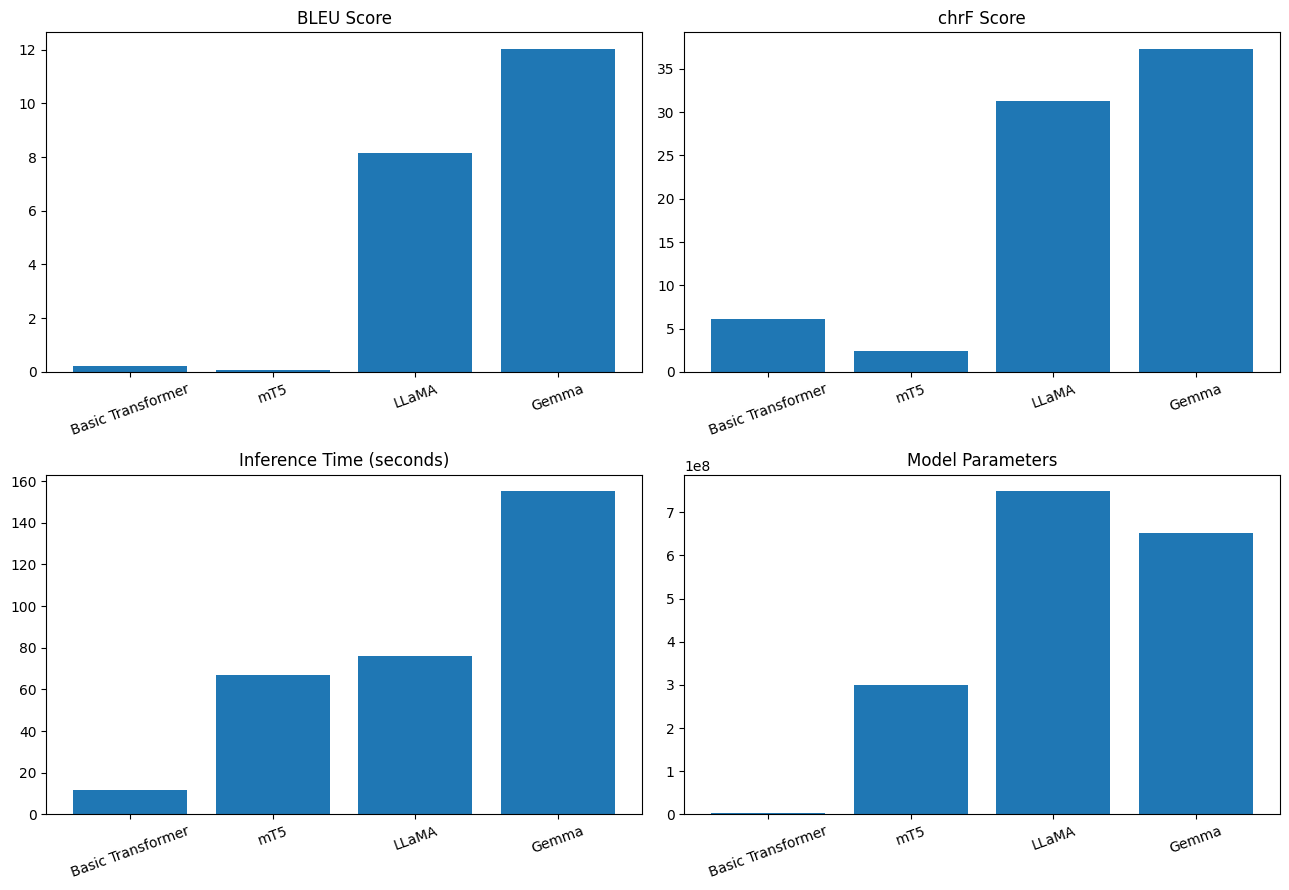

Comparison CSV and graph saved!


In [33]:
import pandas as pd
import matplotlib.pyplot as plt

comparison = pd.DataFrame([
    basic_metrics,
    mt5_metrics,
    llama_metrics,
    gemma_metrics
])

comparison.to_csv("model_comparison.csv", index=False)

print("FINAL MODEL COMPARISON")
print(comparison.to_string(index=False))

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

metrics = [
    ("BLEU", "BLEU Score"),
    ("chrF", "chrF Score"),
    ("Inference_seconds", "Inference Time (seconds)"),
    ("Parameters", "Model Parameters")
]

for ax, (column, title) in zip(axes.flat, metrics):
    ax.bar(comparison["Model"], comparison[column])
    ax.set_title(title)
    ax.tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.savefig("model_comparison.png", dpi=200)
plt.show()

print("Comparison CSV and graph saved!")

In [34]:
translation_comparison = pd.DataFrame({
    "English": sources,
    "Reference_French": references,
    "Basic_Transformer": basic_predictions,
    "mT5": mt5_predictions,
    "LLaMA": llama_predictions,
    "Gemma": gemma_predictions
})

translation_comparison.to_csv(
    "all_model_translations.csv",
    index=False
)

print("Combined translations saved!")
print(translation_comparison.head(5).to_string(index=False))

Combined translations saved!
                                                                                                                             English                                                                                                                                Reference_French                                                                                                                             Basic_Transformer                                                                         mT5                                                                                                      LLaMA                                                                                                                                                Gemma
                                                                 The crowd rapidly increased, and lamentations arose from the roads.                                                                             La foule au

## Responsible and Ethical AI Analysis

### 1. Translation Quality and Hallucinations

The experiment revealed substantial differences in translation quality among the four models.

The Basic Transformer frequently generated unknown tokens (`<unk>`) and repetitive phrases, indicating limitations in vocabulary coverage and contextual understanding.

The fine-tuned mT5 model produced incomplete translations and repeated tokens such as `<extra_id_0>`, demonstrating inadequate adaptation to the translation task.

LLaMA and Gemma generated more fluent French translations but occasionally altered or omitted important information. For example, some generated translations changed the meaning of the original English sentence.

These findings demonstrate that fluent translations are not necessarily accurate translations.

### 2. Bias in Machine Translation

Machine translation models may reproduce gender, cultural, or linguistic biases present in their training datasets. Ambiguous English expressions may be translated using stereotypical gender assumptions.

**Mitigation:** Evaluate translations using diverse demographic and linguistic examples, improve dataset representation, and incorporate human review.

### 3. Cultural Misrepresentation

Idioms, culturally specific expressions, and literary references may lose their intended meaning during translation.

**Mitigation:** Use culturally diverse datasets, evaluate idiomatic expressions separately, and involve bilingual reviewers when cultural accuracy is important.

### 4. Sensitive Content and Misinformation

Incorrect translations involving healthcare, legal matters, personal information, or emergency instructions can create serious consequences.

**Mitigation:** Apply human verification for high-risk translations, protect sensitive data, and avoid relying exclusively on automated translations for critical decisions.

### 5. Responsible Deployment

Machine translation systems should be evaluated for accuracy, fairness, reliability, and transparency before deployment.

BLEU and chrF provide useful quantitative measurements but cannot independently guarantee semantic correctness or cultural appropriateness.

### Conclusion

Gemma achieved the highest BLEU (12.040) and chrF (37.339) scores, demonstrating the strongest translation performance among the four evaluated models.

However, the qualitative examples show that even the better-performing models can produce inaccurate translations. Responsible deployment therefore requires additional testing, transparency, and human oversight.
